# Практическая работа № 5. Классификатор и анализ метрик

**Уровень:** B (данные заданы)
**Цель:** построить модель бинарной классификации и провести анализ качества с учётом цены ошибки: ROC- и PR-кривые, подбор порога классификации.

**Данные:** датасет `breast_cancer` из scikit-learn (569 пациентов, 30 числовых признаков, измеренных по снимкам опухолей). Целевой класс: **1 = злокачественная опухоль** (то, что мы ищем), 0 = доброкачественная. Классы умеренно несбалансированы (примерно 37% / 63%).

**Цена ошибки (условие задачи).** Пропустить злокачественную опухоль (ложноотрицательный результат, FN) намного опаснее, чем направить здорового человека на лишнее обследование (ложноположительный, FP). Принято: **цена FN = 10, цена FP = 1** условных единиц. Если преподаватель выдал другое описание цен — достаточно изменить две переменные `COST_FN` и `COST_FP` в ячейке ниже и перезапустить ноутбук.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

COST_FN = 10   # цена пропущенной болезни
COST_FP = 1    # цена лишнего обследования

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(1 - data.target, name="malignant")      # в sklearn 1 = доброкачественная; перекодируем: 1 = злокачественная
print("Размер:", X.shape)
print("Доля классов (0 — доброкачественная, 1 — злокачественная):")
print(y.value_counts(normalize=True).round(3))

Размер: (569, 30)
Доля классов (0 — доброкачественная, 1 — злокачественная):
malignant
0    0.627
1    0.373
Name: proportion, dtype: float64


## 1. Разбиение и обучение
Разбиение **стратифицированное** (`stratify=y`), чтобы доля классов в train и test была одинаковой. Масштабирование внутри пайплайна — обучается только на train.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, "| доля злокачественных:", round(y_train.mean(), 3))
print("test :", X_test.shape, "| доля злокачественных:", round(y_test.mean(), 3))

model = Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]     # вероятность класса «злокачественная»
print("\nПервые 8 вероятностей:", proba[:8].round(3))

train: (455, 30) | доля злокачественных: 0.374
test : (114, 30) | доля злокачественных: 0.368

Первые 8 вероятностей: [0.    1.    0.043 0.576 0.509 0.001 0.762 0.001]


## 2. ROC- и PR-кривые

ROC-AUC = 0.9960 | Average precision (площадь под PR) = 0.9943


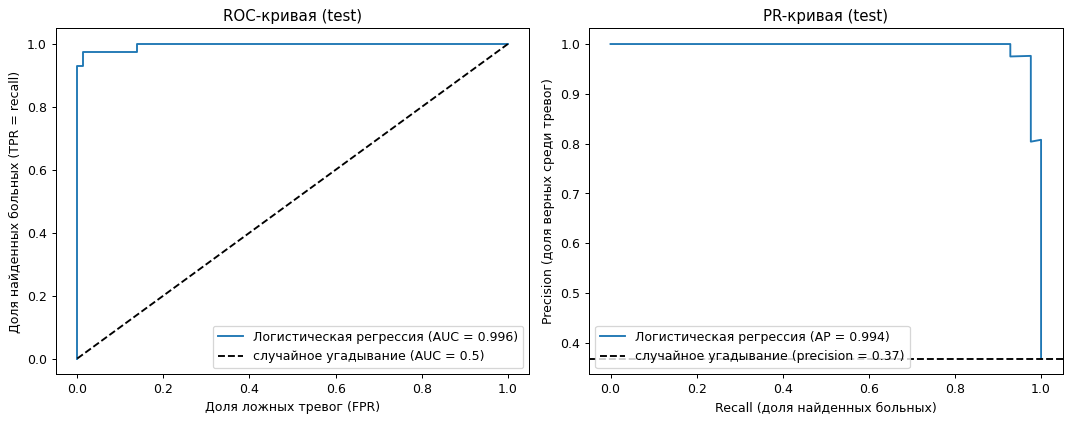

In [3]:
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
ap = average_precision_score(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, label=f"Логистическая регрессия (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="случайное угадывание (AUC = 0.5)")
axes[0].set_title("ROC-кривая (test)")
axes[0].set_xlabel("Доля ложных тревог (FPR)")
axes[0].set_ylabel("Доля найденных больных (TPR = recall)")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, label=f"Логистическая регрессия (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"случайное угадывание (precision = {y_test.mean():.2f})")
axes[1].set_title("PR-кривая (test)")
axes[1].set_xlabel("Recall (доля найденных больных)")
axes[1].set_ylabel("Precision (доля верных среди тревог)")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()
print(f"ROC-AUC = {auc:.4f} | Average precision (площадь под PR) = {ap:.4f}")

**Что означают значения.**
- **ROC-AUC ≈ 0,996** — это вероятность того, что случайно выбранный пациент со злокачественной опухолью получит от модели **более высокую** вероятность, чем случайно выбранный пациент с доброкачественной. 0,5 означает «как случайное угадывание», 1,0 — идеальное разделение классов. Значение 0,996 говорит, что модель почти безошибочно *упорядочивает* пациентов по риску.
- **PR-кривая** (Average precision ≈ 0,994) важнее ROC, когда положительный класс — редкий или когда важна доля ложных тревог среди всех тревог. Здесь классы умеренно несбалансированы (37% положительных), поэтому обе кривые показывают одно и то же — модель сильная. Пунктир на PR-кривой — «качество случайной модели» (precision равен доле положительных, ≈ 0,37).
- Важное замечание: AUC оценивает качество *ранжирования* и не зависит от порога. Он не говорит, какой порог выбрать — для этого нужна цена ошибок.

## 3. Подбор порога под цену ошибки

Порог по умолчанию 0,5 предполагает, что обе ошибки одинаково «дороги». У нас FN в 10 раз дороже FP, значит, порог нужно **снизить**: лучше пометить подозрительным лишнего пациента, чем пропустить больного.

**Как выбираем порог корректно.** Подбирать порог по test нельзя — это была бы утечка: тестовая выборка должна остаться «чистой». Поэтому порог подбирается по **out-of-fold** вероятностям на train (5-кратная кросс-валидация): каждая строка train получает вероятность от модели, которая её не видела. Минимизируем суммарную цену ошибок `COST_FN · FN + COST_FP · FP`.

Минимальная суммарная цена на train (out-of-fold): 36
Пороги с минимальной ценой: [0.18]
Выбранный порог (медиана плато): 0.18
Цена при пороге 0.5 на train (out-of-fold): 84


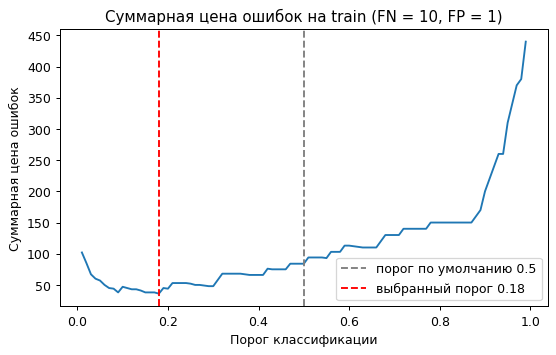

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.01, 0.99, 99)
costs = []
for th in thresholds:
    pred = (oof_proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    costs.append(COST_FN * fn + COST_FP * fp)
costs = np.array(costs)

best = costs.min()
best_threshold = float(np.median(thresholds[costs == best]))   # середина «плато» минимальной цены
print("Минимальная суммарная цена на train (out-of-fold):", best)
print("Пороги с минимальной ценой:", thresholds[costs == best].round(2))
print("Выбранный порог (медиана плато):", round(best_threshold, 2))
print("Цена при пороге 0.5 на train (out-of-fold):", costs[np.argmin(abs(thresholds - 0.5))])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(0.5, color="gray", linestyle="--", label="порог по умолчанию 0.5")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"выбранный порог {best_threshold:.2f}")
plt.title(f"Суммарная цена ошибок на train (FN = {COST_FN}, FP = {COST_FP})")
plt.xlabel("Порог классификации")
plt.ylabel("Суммарная цена ошибок")
plt.legend()
plt.show()

## 4. Сравнение: порог 0,5 и подобранный порог (на test)

In [5]:
def report(th):
    pred = (proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"порог": round(th, 2), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "суммарная цена": COST_FN * fn + COST_FP * fp}

comparison = pd.DataFrame([report(0.5), report(best_threshold)], index=["по умолчанию", "подобранный"]).round(3)
comparison.T

                по умолчанию  подобранный
порог                  0.500        0.180
TN                    71.000       68.000
FP                     1.000        4.000
FN                     3.000        1.000
TP                    39.000       41.000
accuracy               0.965        0.956
precision              0.975        0.911
recall                 0.929        0.976
F1                     0.951        0.943
суммарная цена        31.000       14.000

**Вывод по сравнению (test: 114 пациентов, из них 42 со злокачественной опухолью).**

| | Порог 0,5 | Порог 0,18 |
|---|---|---|
| Пропущено больных (FN) | 3 | **1** |
| Лишних тревог (FP) | 1 | 4 |
| Recall | 0,929 | **0,976** |
| Precision | **0,975** | 0,911 |
| Accuracy | **0,965** | 0,956 |
| F1 | **0,951** | 0,943 |
| Суммарная цена (FN×10 + FP×1) | 31 | **14** |

- Снижение порога с 0,5 до 0,18 уменьшило число пропущенных больных с 3 до 1 (recall вырос с 0,929 до 0,976), ценой трёх дополнительных ложных тревог (precision упал с 0,975 до 0,911). Так как FN в 10 раз дороже FP, **суммарная цена ошибок снизилась более чем вдвое (31 → 14)**.
- Accuracy и F1 при этом чуть *ухудшились*. Это важный урок: эти метрики считают обе ошибки одинаково «дорогими» и поэтому не видят улучшения, которое нам нужно. Метрику нужно выбирать по цене ошибки: здесь это **recall** (не пропустить больного) при контролируемом precision и итоговая **суммарная цена**.
- Порог 0,18 выбран по out-of-fold вероятностям на train и применён к test один раз, поэтому оценка честная.
- *Оговорка:* на test всего 42 положительных примера, и разница в 2 пациента (3 FN → 1 FN) статистически не слишком надёжна. Направление эффекта согласуется с результатом на train (цена out-of-fold 84 → 36), но для уверенного вывода нужно больше данных или повторная проверка на других разбиениях.

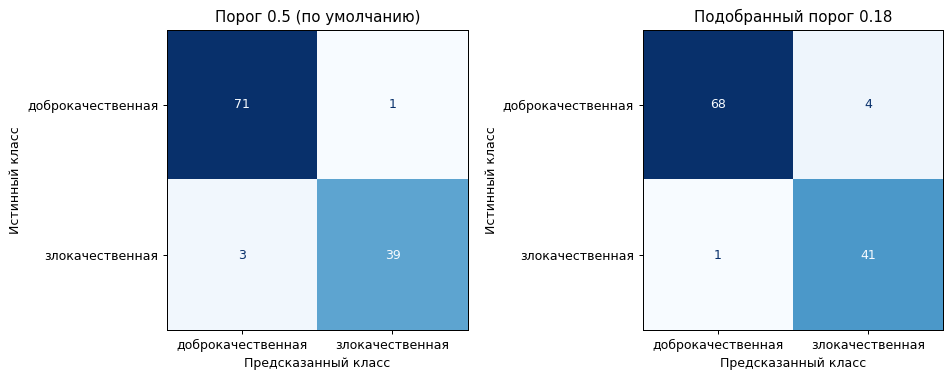

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, th, title in zip(axes, [0.5, best_threshold], ["Порог 0.5 (по умолчанию)", f"Подобранный порог {best_threshold:.2f}"]):
    cm = confusion_matrix(y_test, (proba >= th).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["доброкачественная", "злокачественная"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
plt.tight_layout()
plt.show()

## 5. Итоговый вывод

- Логистическая регрессия очень хорошо разделяет классы (ROC-AUC ≈ 0,996), но порог 0,5 не соответствует условию задачи, где пропущенная болезнь в 10 раз хуже лишней тревоги.
- Подобранный порог **0,18** (по out-of-fold вероятностям train) снижает суммарную цену ошибок на test с 31 до 14 за счёт роста recall с 0,929 до 0,976.
- Использовать accuracy как единственную метрику нельзя: она ухудшилась там, где на самом деле стало лучше с точки зрения цены ошибки.
- Если изменить цены ошибок (`COST_FN`, `COST_FP`), подобранный порог изменится — достаточно перезапустить ноутбук.